# Canal 2, gene axis: is the EPISTEMIC term also concentrated on the genes the model predicts worst?

The same reading as `classic.ipynb`, applied to the three post-hoc epistemic estimators. The head's own spread is not drawn here: it is the subject of that other notebook.

Grouping is `(gene, slide)`, so the error is ranked **across the spots of one gene**. Slides are folded to one controlled correlation per gene, genes are split into deciles of their own prediction accuracy, and the median absolute correlation of each decile is plotted. Worst-predicted genes on the left, so a **decline left to right** means the correlation lives on the genes the model predicts worst.

### One accuracy for every source, and why

The x axis is **one accuracy per (cohort, gene)**, built once from the `pr_classic3` runs: per `(donor, gene)` from `benchmark_summary.parquet`, then averaged over donors, then over the heads listed below. It is the ordering of the accuracy and calibration results.

Three reasons not to give each source its own accuracy. A shared axis is what makes the four curves comparable at all. The deep-ensemble members are trained with `compute_final_metrics: false`, so they write no `atoms.parquet` and have no per-gene accuracy of their own. And the epistemic post-hoc estimators do not change the mean much: the Laplace mean of a Gaussian head **is** the MAP mean, so its accuracy is by construction that of the run.

**The one place this is approximate: the deep ensemble.** Its mean is the average of the member means, so its true per-gene accuracy is slightly above the single-model one. The gene ORDERING is what the axis uses, and it barely moves, but a value read off this axis is the single-model accuracy, not the ensemble's.

### Sources come from different training arms

`own` is `pr_classic3`, the post-hoc estimators are `pr_classic1`, the deep ensemble is `de_6`. These are different launches of the same sweep, not the same weights; the measured gap on point estimates is about $0.002$. Negligible against a difference between sources of order $0.05$, not against one of $0.005$.

Run on cluster Jupyter.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))

# =============================== SETTINGS ====================================
DATASETS = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS   = "r75"
CASE     = "lin_pos"
CHANNEL  = "epistemic"     # "epistemic" | "total" | "aleatoric"

# One figure ROW per head. The heads mute on the gene axis (gene-homoscedastic
# Gaussian, constant variance within the group; Poisson, variance = mean) have
# no place here.
HEADS = ["heteroscedastic", "negativebinomial_hetero_noanchor_cp"]

# The leaf carries the lambda_ segment for the Gaussian family in the single-model tree, and none
# at all for the count family. On the ensemble side the lambda_ segment disappears.
MODEL_LEAF = {
    "heteroscedastic":                      "heteroscedastic/lambda_0.0",
    "homoscedastic":                        "homoscedastic/lambda_0.0",
    "spot_homoscedastic":                   "spot_homoscedastic/lambda_0.0",
    "poisson_cp":                           "poisson_cp",
    "negativebinomial_hetero_noanchor_cp":  "negativebinomial_hetero_noanchor_cp",
}

_SUB_MC = {"total": "canal2_total_mc", "epistemic": "canal2_epistemic",
           "aleatoric": "canal2_aleatoric_mc"}
SOURCES = [
    dict(key="mc",  label="pr_classic1", run_id="pr_classic1", ens=False,
         sub=_SUB_MC[CHANNEL],                name=f"MC-dropout ({CHANNEL})"),
    dict(key="lap", label="pr_classic1", run_id="pr_classic1", ens=False,
         sub=f"canal2_laplace_{CHANNEL}",     name=f"Laplace ({CHANNEL})"),
    dict(key="de",  label="de_6",        run_id="de_6",        ens=True,
         sub=f"canal2_uncertainty/{CHANNEL}", name=f"Deep ensemble ({CHANNEL})"),
]

ACC_RUN     = dict(label="pr_classic3", run_id="pr_classic3")   # where the x axis comes from
RANK_METRIC = "pearson"
NBINS       = 10           # accuracy deciles
FIGDIR      = PROJ / "results" / "_analysis" / "figures"
# =============================================================================

N_PLUS_MIN, CONVENTION = 60, "v3_native_scale"
N_COL = {"lin_all": "n_plus_all", "lin_pos": "n_plus_pos", "log_pos": "n_plus_pos"}
MIN_SLIDES = 3

# One color per SOURCE, never per model: here the models are the ROWS, named on the
# y axis, and the color encodes only the source. Same palette as canal2_uncertainty_vs_error_epistemic.ipynb.
# Do not carry this palette into a figure where a model would be encoded by a color.
SOURCE_COLORS = {"mc": "b", "lap": "g", "de": "r"}
MODEL_LABELS = {
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}


def canal2_dir(src, ds, model):
    """The canal2 folder of a (source, cohort, head). Three path families: the
    single-model tree carries a lambda_ segment for the Gaussians, the ensemble tree goes through
    .../ensemble/ and carries none."""
    base = (PROJ / "results" / ds / src["run_id"]
            / f"_{ds}_hvg_top3000" / RADIUS)
    leaf = model if src["ens"] else MODEL_LEAF[model]
    return (base / leaf / "ensemble" / src["sub"]) if src["ens"] else (base / leaf / src["sub"])


PAIR, missing, stale, na = {}, [], [], []
for src in SOURCES:
    for ds in DATASETS:
        for m in HEADS:
            d = canal2_dir(src, ds, m)
            if not (d / "summary.json").is_file():
                missing.append((src["key"], ds, m))
                continue
            s = json.loads((d / "summary.json").read_text())
            if s.get("not_applicable"):
                na.append((src["key"], ds, m))
                continue
            if s.get("canal2_convention") != CONVENTION:
                stale.append((src["key"], ds, m, s.get("canal2_convention")))
                continue
            f = d / "pair_partial.parquet"
            if f.is_file():
                PAIR[(src["key"], ds, m)] = pd.read_parquet(f)

print(f"case = {CASE!r}   canal = {CHANNEL!r}")
print(f"INVENTORY, out of a maximum of {len(DATASETS) * len(HEADS)} per source")
for src in SOURCES:
    got = sum(1 for (k, _, _) in PAIR if k == src["key"])
    print(f"  {src['name']:<28s} {src['label']:<13s} {src['sub']:<34s} {got:>2d} run(s)")
if stale:
    print(f"\n(!) {len(stale)} run(s) NOT conforming to canal2_convention={CONVENTION!r}, DROPPED: "
          f"{stale[:6]}")
if na:
    print(f"\n{len(na)} run(s) 'not_applicable' : {na[:6]}")
if missing:
    print(f"\n(!) {len(missing)} (source, cohort, head) with no summary.json :")
    for k in sorted({x[0] for x in missing}):
        w = [f"{ds}/{m}" for (kk, ds, m) in missing if kk == k]
        print(f"    {k:<5s} {len(w):>2d} : {w[:4]}{' ...' if len(w) > 4 else ''}")

_arms = sorted({s["label"] for s in SOURCES})
if len(_arms) > 1:
    print(f"\n(!) The sources come from {len(_arms)} training arms : {_arms}.")
    print("    Two LAUNCHES of the same sweep, not the same weights; measured gap ~0.002.")

case = 'lin_pos'   canal = 'epistemic'
INVENTORY, out of a maximum of 6 per source
  MC-dropout (epistemic)       pr_classic1   canal2_epistemic                    6 run(s)
  Laplace (epistemic)          pr_classic1   canal2_laplace_epistemic            6 run(s)
  Deep ensemble (epistemic)    de_6          canal2_uncertainty/epistemic        6 run(s)

(!) The sources come from 2 training arms : ['de_6', 'pr_classic1'].
    Two LAUNCHES of the same sweep, not the same weights; measured gap ~0.002.


In [2]:
# ── THE X AXIS : one accuracy per (cohort, gene), shared by all the sources ───────────────
# Donor cascade, the one from src/evaluation/benchmark_summary.py: one value per (donor, gene),
# then mean over the donors, then mean over the listed heads. Intersection of the genes
# present in every head, otherwise a gene missing from one head would shift the axis.
ACC = {}
for ds in DATASETS:
    pieces, shared = [], None
    for m in HEADS:
        f = (PROJ / "results" / ds / ACC_RUN["run_id"]
             / f"_{ds}_hvg_top3000" / RADIUS / MODEL_LEAF[m] / "benchmark_summary.parquet")
        if not f.is_file():
            print(f"  (!) no benchmark_summary.parquet for {ds} / {m}")
            continue
        b = pd.read_parquet(f)
        if RANK_METRIC not in b.columns or "gene" not in b.columns:
            print(f"  (!) {RANK_METRIC} absent de {f}")
            continue
        per_gene = b.groupby("gene")[RANK_METRIC].mean()      # mean over the donors
        shared = set(per_gene.index) if shared is None else (shared & set(per_gene.index))
        pieces.append(per_gene)
    if not pieces or not shared:
        print(f"  (!) {ds}: accuracy axis impossible to build")
        continue
    shared = sorted(shared)
    ACC[ds] = (pd.concat([p.loc[shared] for p in pieces], axis=1).mean(axis=1)
                 .rename("pred_corr").reset_index())
    print(f"  {DATASET_LABELS[ds]:<22s} axis on {len(ACC[ds]):,} shared genes, "
          f"{len(pieces)} head(s) averaged")


# ── THE VALUE : one controlled correlation per gene, the slides folded ────────────────────────
def gene_level(frame):
    """The slides folded with a weight equal to the group size, the canal 2 cascade."""
    col, ncol = f"r_partial_{CASE}", N_COL[CASE]
    if frame is None or col not in frame.columns:
        return None
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna()]
    if d.empty:
        return None
    t = pd.DataFrame({"gene": d["gene"].to_numpy(),
                      "w":    d[ncol].to_numpy(float),
                      "wr":   d[ncol].to_numpy(float) * d[col].to_numpy(float)})
    g = t.groupby("gene", sort=True)
    out = pd.DataFrame({"r": g["wr"].sum() / g["w"].sum(), "n_slides": g.size()}).reset_index()
    return out[out["n_slides"] >= MIN_SLIDES]


GL = {}
for (k, ds, m), frame in PAIR.items():
    gl = gene_level(frame)
    if gl is None or ds not in ACC:
        continue
    d = gl.merge(ACC[ds], on="gene")
    GL[(k, ds, m)] = d[np.isfinite(d["pred_corr"]) & np.isfinite(d["r"])]
print(f"\n{len(GL)} curves (source, cohort, head) ready")

  Tumor Profiler         axis on 3,000 shared genes, 2 head(s) averaged
  Kidney/Lung with TLS   axis on 3,000 shared genes, 2 head(s) averaged
  NSCLC                  axis on 3,000 shared genes, 2 head(s) averaged

18 curves (source, cohort, head) ready


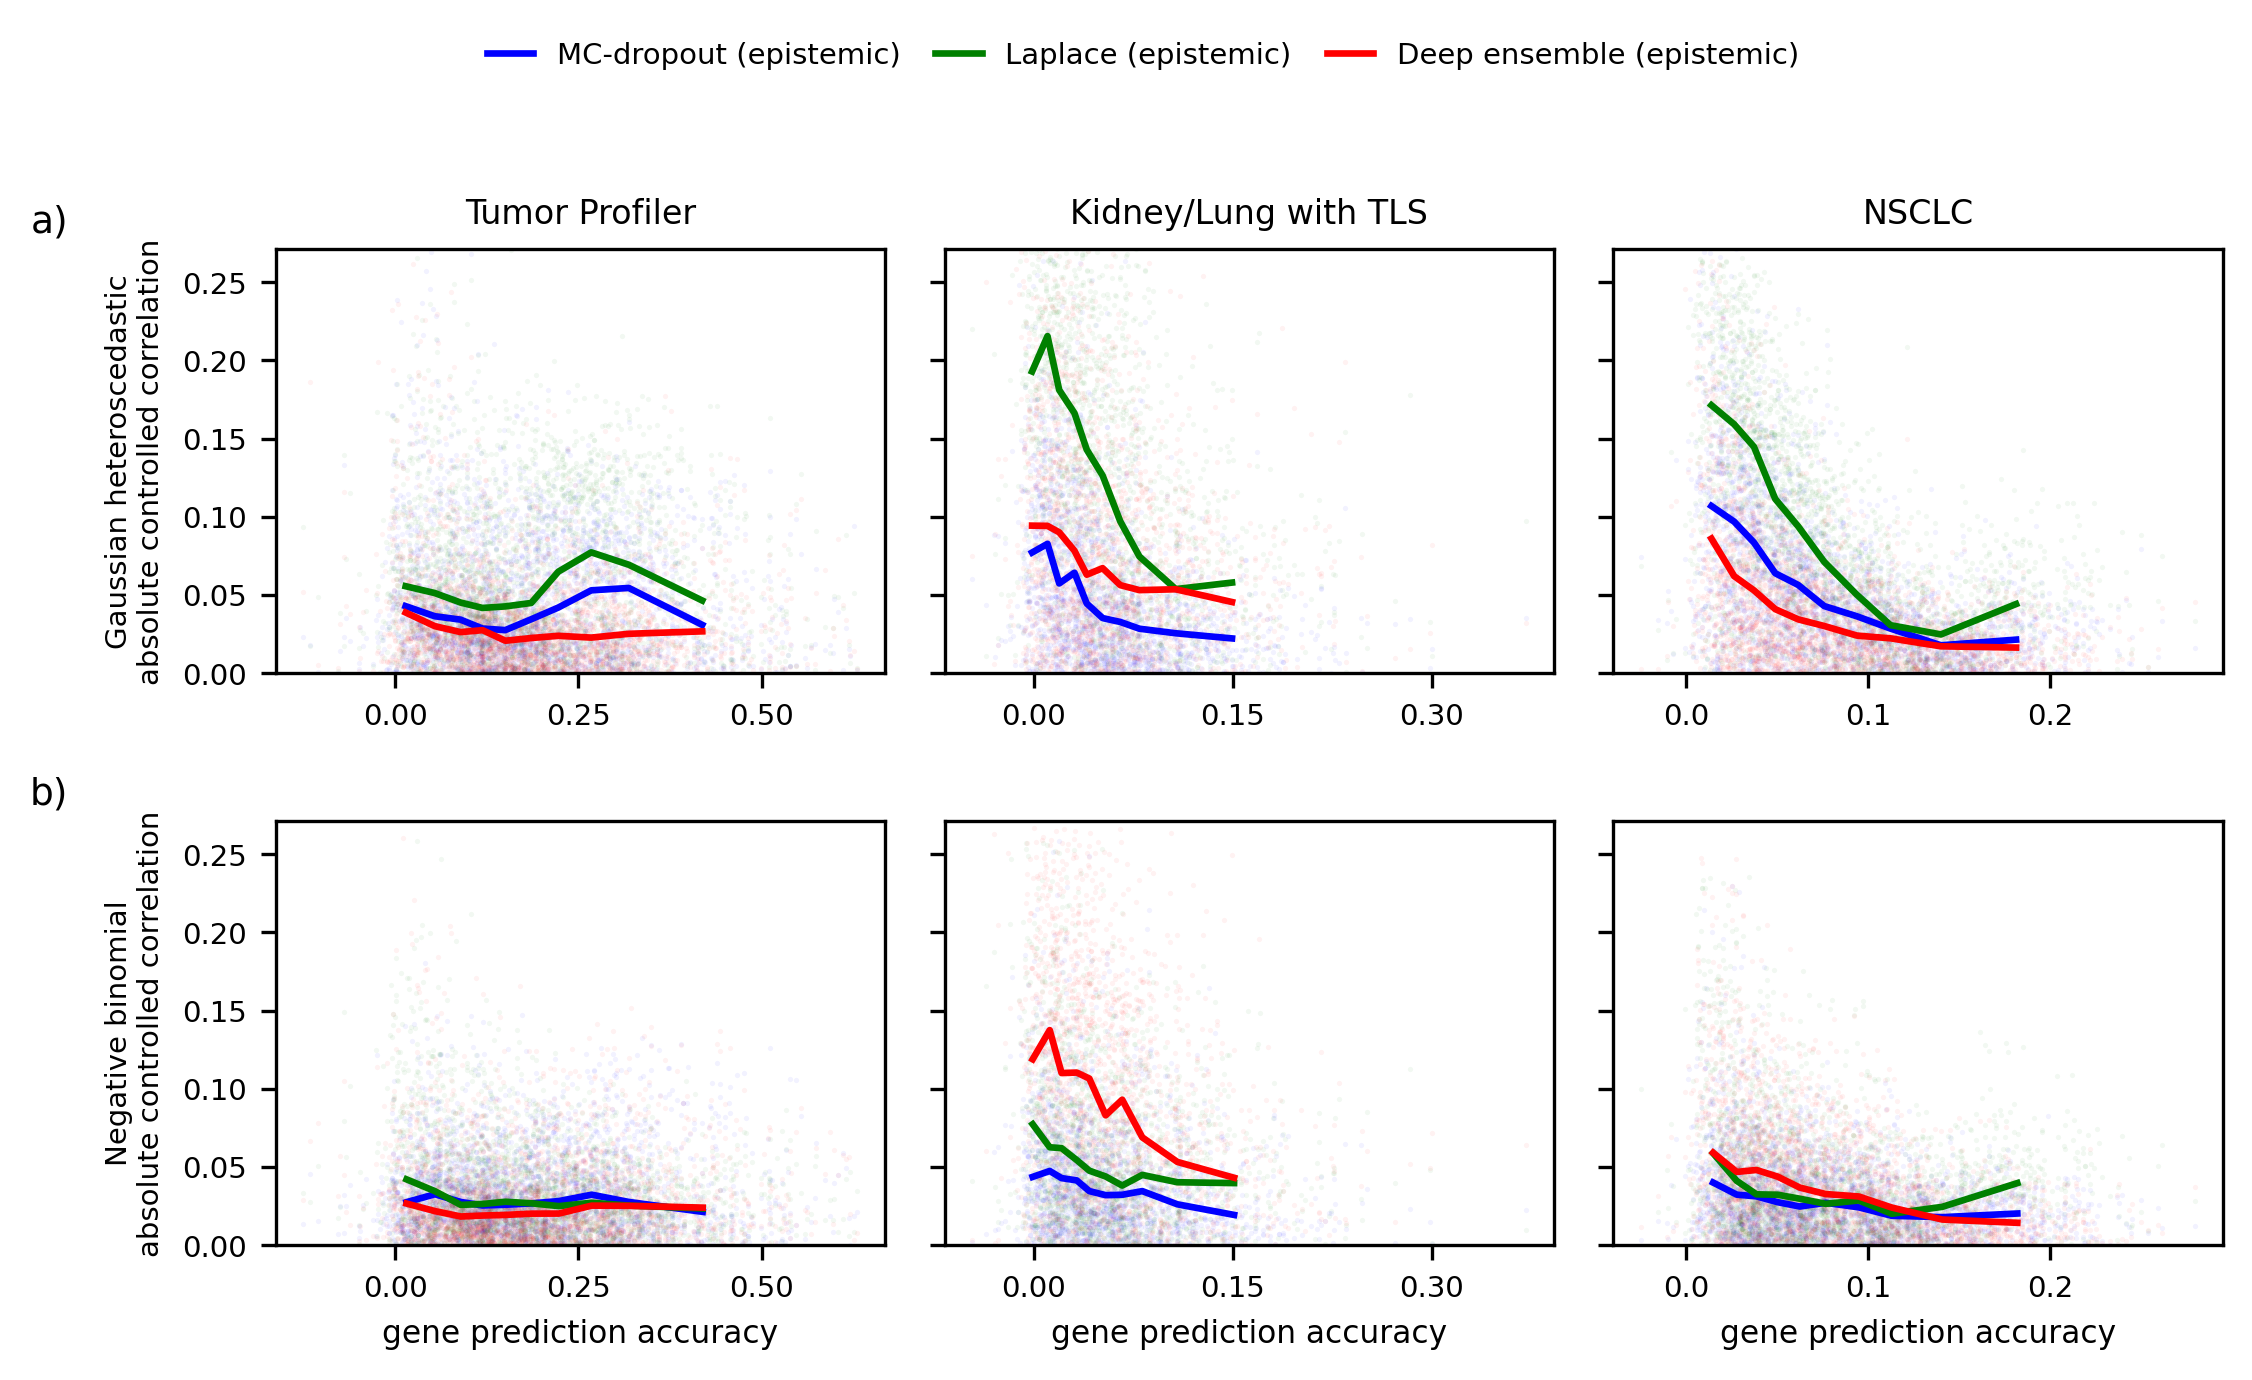

## FIGURE  fig_canal2_gene_axis_predictability_epistemic_lin_pos.pdf
## TITLE   The controlled error-uncertainty correlation of each uncertainty source, against how well the gene is predicted
## CAPTION Error definition: |y - mu|, detected entries only (y > 0). Grouping: one group per gene
## CAPTION and slide, ranking the error across the spots of that gene.
## CAPTION Rows are the predictive heads, columns the three cohorts, colors the uncertainty
## CAPTION sources: the epistemic term of Monte Carlo dropout, of a Laplace approximation and of
## CAPTION a deep ensemble. The head's own spread is not drawn here.
## CAPTION One translucent point per gene and per source, its prediction accuracy against the
## CAPTION absolute value of its controlled correlation; the line is the median over 10 deciles
## CAPTION of that accuracy. Absolute, because genes of opposite sign would otherwise cancel.
## CAPTION The view is clipped at the 99th percentile, which leaves 1.0% of the genes
## CAPTION

In [3]:
FIGDIR.mkdir(parents=True, exist_ok=True)


def fig_show(fig, stem, title, caption):
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")


# The scatter: one point per gene and per source. rasterized=True keeps the PDF light, the line and
# the text stay vector. The view is bounded at a percentile, otherwise a few extreme genes
# stretch the axis and flatten the medians down at zero.
SCATTER_S     = 1.6
SCATTER_ALPHA = 0.05
YCLIP_Q       = 99.0

all_abs = (np.concatenate([GL[k]["r"].abs().to_numpy() for k in GL]) if GL
           else np.array([0.0]))
y_hi  = float(np.nanpercentile(all_abs, YCLIP_Q))
above = float((all_abs > y_hi).mean())

fig, axes = plt.subplots(len(HEADS), len(DATASETS),
                         figsize=(2.5 * len(DATASETS), 2.3 * len(HEADS)),
                         dpi=300, sharey="row")
axes = np.atleast_2d(axes)
drawn = []
for i, m in enumerate(HEADS):
    for j, ds in enumerate(DATASETS):
        ax = axes[i, j]
        for src in SOURCES:
            d = GL.get((src["key"], ds, m))
            if d is None or d.empty:
                continue
            b = pd.qcut(d["pred_corr"], NBINS, labels=False, duplicates="drop")
            gb = d.assign(abs_r=d["r"].abs()).groupby(b, observed=True)
            x, y, s = (gb["pred_corr"].median().to_numpy(), gb["abs_r"].median().to_numpy(),
                       gb["r"].median().to_numpy())
            ax.scatter(d["pred_corr"], d["r"].abs(), s=SCATTER_S, alpha=SCATTER_ALPHA,
                       color=SOURCE_COLORS[src["key"]], linewidths=0, rasterized=True, zorder=1)
            ax.plot(x, y, "-", lw=1.6, color=SOURCE_COLORS[src["key"]], zorder=3)
            rho = float(d["r"].abs().corr(d["pred_corr"], method="spearman"))
            for xi, yi, si, ni in zip(x, y, s, gb.size().to_numpy()):
                drawn.append(dict(cohort=ds, head=m, source=src["key"], acc_bin_median=xi,
                                  abs_assoc_median=yi, assoc_median=si, n_genes=int(ni),
                                  rho_genes=rho))
        ax.set_ylim(0.0, y_hi)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.tick_params(labelsize=7)
        if i == 0:
            ax.set_title(DATASET_LABELS[ds], fontsize=8)
        if i == len(HEADS) - 1:
            ax.set_xlabel("gene prediction accuracy", fontsize=7.5)
        if j == 0:
            ax.set_ylabel(f"{MODEL_LABELS.get(m, m)}\nabsolute controlled correlation",
                          fontsize=7)
            ax.text(-0.34, 1.02, f"{'abcd'[i]})", transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=9)

handles = [Line2D([], [], color=SOURCE_COLORS[s["key"]], lw=1.6, label=s["name"])
           for s in SOURCES if any(k[0] == s["key"] for k in GL)]
fig.tight_layout(rect=(0, 0, 1, 0.90))
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3,
           frameon=False, fontsize=7, handlelength=1.6, columnspacing=1.2)

fig_show(fig, FIGDIR / f"fig_canal2_gene_axis_predictability_{CHANNEL}_{CASE}",
         f"The controlled error-uncertainty correlation of each uncertainty source, against how "
         f"well the gene is predicted",
         ["Error definition: |y - mu|, detected entries only (y > 0). Grouping: one group per gene",
          "and slide, ranking the error across the spots of that gene.",
          "Rows are the predictive heads, columns the three cohorts, colors the uncertainty",
          f"sources: the {CHANNEL} term of Monte Carlo dropout, of a Laplace approximation and of",
          "a deep ensemble. The head's own spread is not drawn here.",
          "One translucent point per gene and per source, its prediction accuracy against the",
          f"absolute value of its controlled correlation; the line is the median over {NBINS} deciles",
          "of that accuracy. Absolute, because genes of opposite sign would otherwise cancel.",
          f"The view is clipped at the {YCLIP_Q:g}th percentile, which leaves {above:.1%} of the genes",
          "above the frame; they are in the median but not drawn.",
          "Worst predicted genes on the left, so a decline left to right means the correlation",
          "lives on the genes the model predicts worst.",
          "ONE accuracy per cohort and gene, shared by every source and built once from the",
          "pr_classic3 runs: per donor and gene, then averaged over donors and over heads. A shared",
          "axis is what makes the sources comparable; the deep-ensemble members write no per-gene",
          "accuracy of their own, and its mean prediction differs slightly from the single model's,",
          "so a value read off this axis is the single-model accuracy.",
          "The sources come from two launches of the same sweep, not the same weights; the",
          "measured gap on point estimates is about 0.002."])

print()
print("=" * 96)
print("THE PRINTED TWIN - the slope, one number per (cohort, head, source)")
print("=" * 96)
D = pd.DataFrame(drawn)
if not D.empty:
    slope = (D.groupby(["cohort", "head", "source"])["rho_genes"].first().reset_index())
    piv = slope.pivot_table(index=["cohort", "head"], columns="source", values="rho_genes")
    print(piv.round(3).to_string())
    print()
    print("rho = Spearman over ALL the genes between the gene's accuracy and the ABSOLUTE value of its")
    print("      controlled correlation. NEGATIVE = the correlation lives on badly predicted genes.")
    print()
    print("=" * 96)
    print("THE PRINTED TWIN - the plotted points")
    print("=" * 96)
    for ds in DATASETS:
        for m in HEADS:
            sub = D[(D["cohort"] == ds) & (D["head"] == m)]
            if sub.empty:
                continue
            print(f"\n--- {DATASET_LABELS[ds]} / {MODEL_LABELS.get(m, m)} ---")
            print(sub.pivot_table(index="acc_bin_median", columns="source",
                                  values="abs_assoc_median").round(4).to_string())
else:
    print("(!) nothing plotted -- check the inventory in cell 2")